In [ ]:
import os
import cv2
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchvision.models import vgg16
import torch.nn as nn
from torch.optim import Adam
from PIL import UnidentifiedImageError

# Định nghĩa đường dẫn dữ liệu
data_path = '/content/drive/MyDrive/KHKT/Dataset(7class)'

# Định nghĩa các biến biến đổi dữ liệu hình ảnh
transformations = transforms.Compose([transforms.ToTensor(), transforms.Resize((224, 224))])

# Tạo dataset từ dữ liệu hình ảnh cho cả 3 thư mục
train_dataset = ImageFolder(root=os.path.join(data_path, 'test'), transform=transformations)
test_dataset = ImageFolder(root=os.path.join(data_path, 'test'), transform=transformations)
valid_dataset = ImageFolder(root=os.path.join(data_path, 'valid'), transform=transformations)

In [ ]:
# Tạo DataLoader cho tập huấn luyện, tập kiểm tra và tập validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)
valid_loader = DataLoader(valid_dataset, batch_size=32)

In [ ]:
# Tạo mô hình VGG16 với trọng số đã được đào tạo trước đó
model = vgg16(pretrained=True)

# Thay đổi lớp cuối cùng để phù hợp với số lớp đầu ra của bài toán (ở đây là 7 lớp)
model.classifier[6] = nn.Linear(4096, 7)

# Chọn thiết bị tính toán (GPU hoặc CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Chuyển mô hình và dữ liệu lên thiết bị đã chọn
clf = model.to(device)
optimizer = Adam(clf.parameters(), lr=1e-5)
loss_fn = nn.CrossEntropyLoss()

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:07<00:00, 70.6MB/s]


In [ ]:
# Huấn luyện mô hình
num_epochs = 10
for epoch in range(num_epochs):
    running_loss = 0.0
    for inputs, labels in train_loader:
        try:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = clf(inputs)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        except UnidentifiedImageError:
            print(f"Skipped an image due to UnidentifiedImageError:")
        except PIL.UnidentifiedImageError:
            print(f"Skipped an image due to PIL.UnidentifiedImageError:")

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/PIL/Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [ ]:
# Lưu mô hình vào một tệp tin
model_save_path = '/content/drive/MyDrive/KHKT/modelmodel7classvgg16.h5'
torch.save(clf.state_dict(), model_save_path, _use_new_zipfile_serialization=False)

print(f"Model saved to {model_save_path}")

In [ ]:
from sklearn.metrics import classification_report

# Đánh giá độ chính xác của mô hình trên tập kiểm tra
correct = 0
total = 0
predicted_labels = []
true_labels = []

with torch.no_grad():
    for data in test_loader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = clf(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        predicted_labels.extend(predicted.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

accuracy = 100 * correct / total
print(f'Accuracy of the network on the test data: {accuracy:.2f} %')

# Tính và hiển thị các số liệu
report = classification_report(true_labels, predicted_labels, target_names=train_dataset.classes)
print("Classification Report:")
print(report)


/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/PIL/Image.py:996: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Accuracy of the network on the test data: 97.94 %
Classification Report:
              precision    recall  f1-score   support

   cardboard       1.00      0.96      0.98       242
     e-waste       0.98      1.00      0.99       302
       glass       0.96      1.00      0.98       254
     medical       0.98      0.97      0.97       197
       metal       0.98      0.99      0.99       260
       paper       0.99      0.96      0.98       270
     plastic       0.97      0.97      0.97       268

    accuracy                           0.98      1793
   macro avg       0.98      0.98      0.98      1793
weighted avg       0.98      0.98      0.98      1793



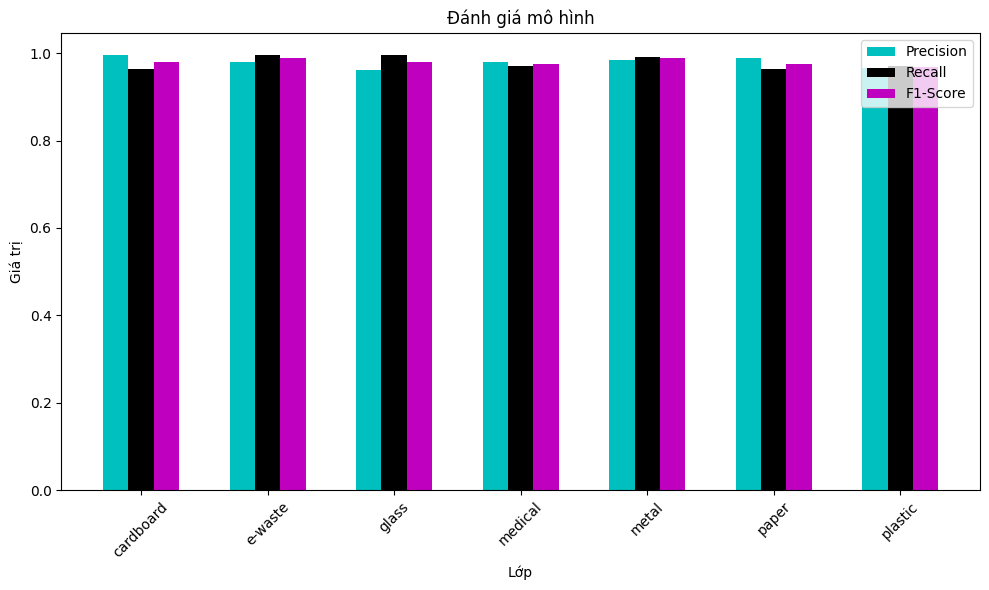

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import numpy as np

# Đánh giá mô hình và tính số liệu
report = classification_report(true_labels, predicted_labels, target_names=train_dataset.classes, output_dict=True)

# Lấy precision, recall và F1-score từ báo cáo
precision = [report[label]['precision'] for label in train_dataset.classes]
recall = [report[label]['recall'] for label in train_dataset.classes]
f1_score = [report[label]['f1-score'] for label in train_dataset.classes]

# Xác định tên lớp
labels = train_dataset.classes

# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(10, 6))
index = np.arange(len(labels))
bar_width = 0.2

plt.bar(index, precision, bar_width, label='Precision', color='c', align='center')
plt.bar(index + bar_width, recall, bar_width, label='Recall', color='k', align='center')
plt.bar(index + 2 * bar_width, f1_score, bar_width, label='F1-Score', color='m', align='center')

plt.xlabel('Lớp')
plt.ylabel('Giá trị')
plt.title('Đánh giá mô hình')
plt.xticks(index + bar_width, labels, rotation=45)
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

# Đánh giá mô hình và tính số liệu
report = classification_report(true_labels, predicted_labels, target_names=train_dataset.classes, output_dict=True)

# Tạo DataFrame từ báo cáo
df = pd.DataFrame(report).transpose()

# In bảng đánh giá
print("Classification Report:")
print(df)


Classification Report:
              precision    recall  f1-score      support
cardboard      0.995726  0.962810  0.978992   242.000000
e-waste        0.980456  0.996689  0.988506   302.000000
glass          0.961977  0.996063  0.978723   254.000000
medical        0.979487  0.969543  0.974490   197.000000
metal          0.984733  0.992308  0.988506   260.000000
paper          0.988593  0.962963  0.975610   270.000000
plastic        0.966543  0.970149  0.968343   268.000000
accuracy       0.979364  0.979364  0.979364     0.979364
macro avg      0.979645  0.978646  0.979024  1793.000000
weighted avg   0.979559  0.979364  0.979340  1793.000000


NameError: name 'df' is not defined

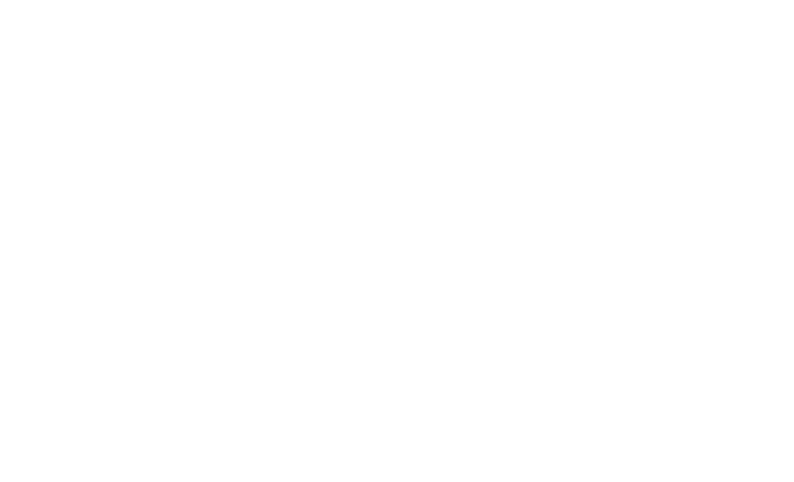

In [1]:
import matplotlib.pyplot as plt

# Tạo bảng đánh giá
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('tight')
ax.axis('off')
ax.table(cellText=df.values, colLabels=df.columns, cellLoc='center', loc='center')

# Lưu bảng thành hình ảnh
plt.savefig('classification_report.png')
plt.show()


Classification Report:
              precision    recall  f1-score   support

   cardboard       1.00      0.96      0.98       242
     e-waste       0.98      1.00      0.99       302
       glass       0.96      1.00      0.98       254
     medical       0.98      0.97      0.97       197
       metal       0.98      0.99      0.99       260
       paper       0.99      0.96      0.98       270
     plastic       0.97      0.97      0.97       268

    accuracy                           0.98      1793
   macro avg       0.98      0.98      0.98      1793
weighted avg       0.98      0.98      0.98      1793



IndexError: ignored

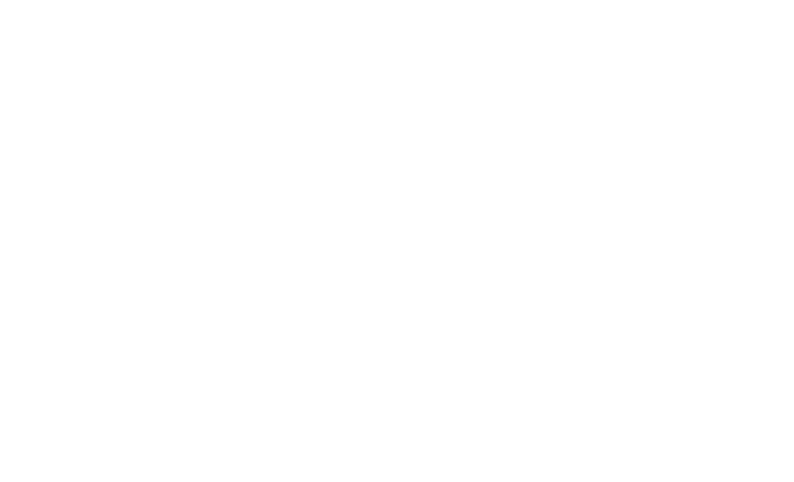

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Đánh giá mô hình và tính số liệu
report = classification_report(true_labels, predicted_labels, target_names=train_dataset.classes)

# In bảng đánh giá
print("Classification Report:")
print(report)

# Tạo hình ảnh từ báo cáo
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')  # Tắt trục
ax.table(cellText=[report.split('\n')], loc='center', cellLoc='center', colLabels=["", "precision", "recall", "f1-score", "support"])
plt.title("Classification Report")

# Lưu bảng thành hình ảnh
plt.savefig('classification_report.png')
plt.show()
